### Installing OpenCV and Caer Module

In [1]:
!pip install opencv-contrib-python
!pip install caer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 809.5/809.5 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 52.4 MB/s eta 0:00:00


### Reading and Showing Photos and Videos uisng CV

In [2]:
import cv2 as cv

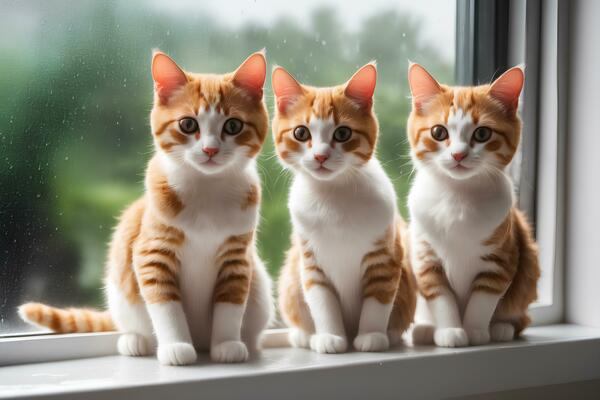

-1

In [3]:
img=cv.imread("/content/Cat.jpg")
from google.colab.patches import cv2_imshow
cv2_imshow(img)
cv.waitKey(0)

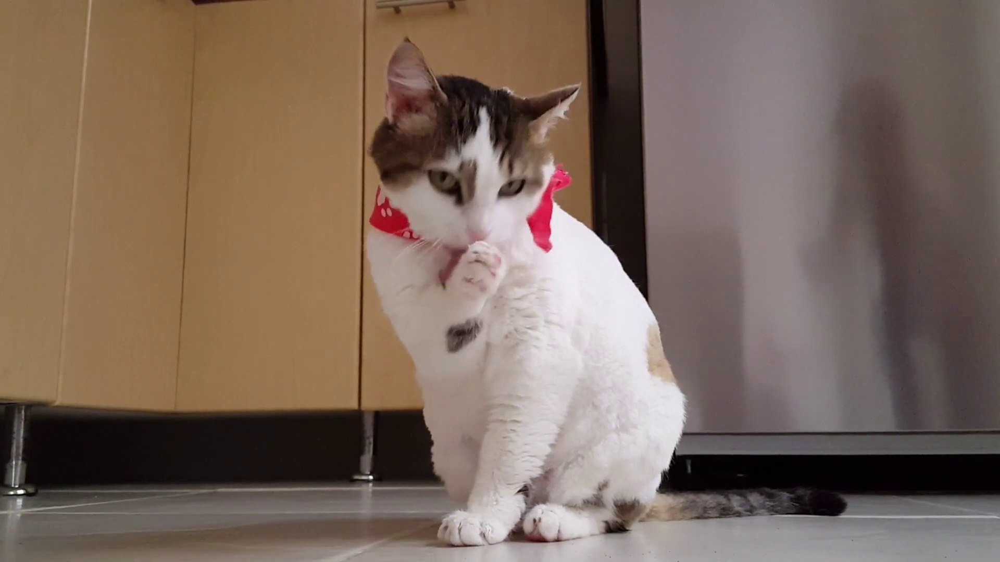

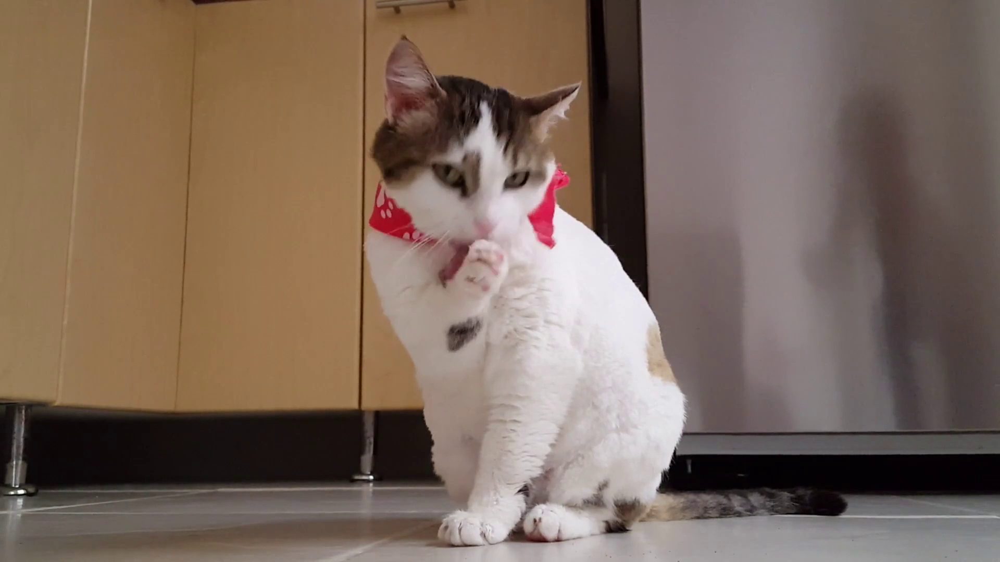

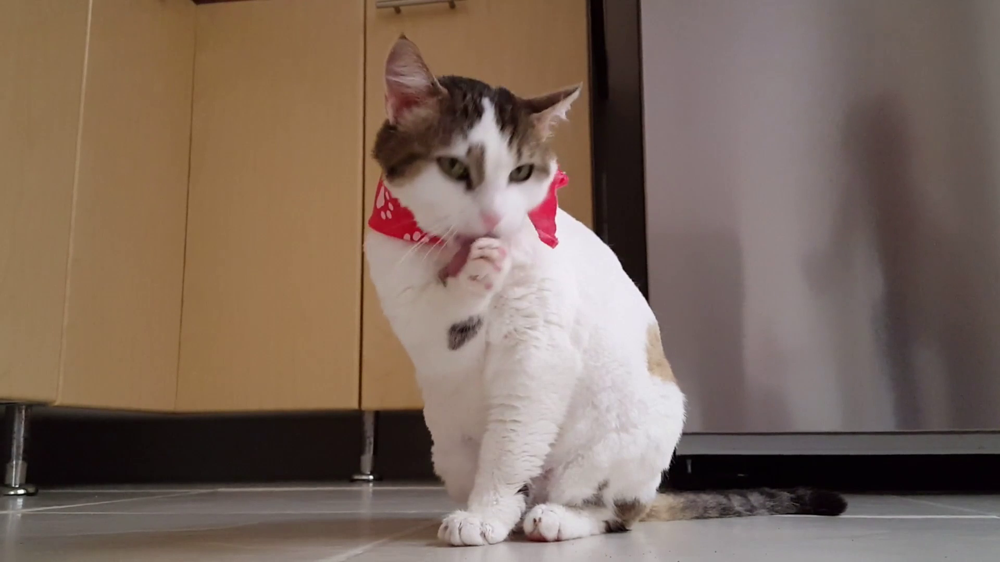

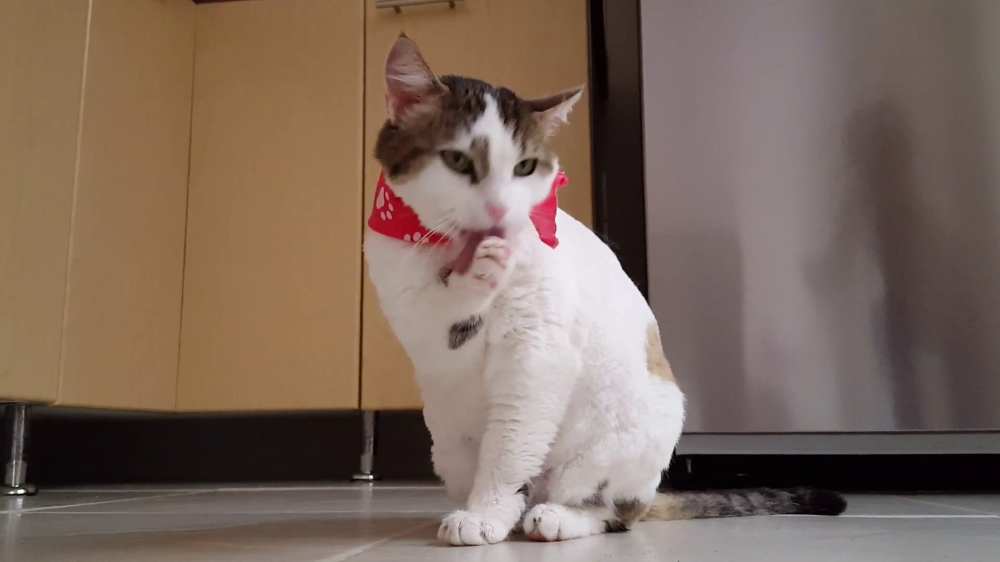

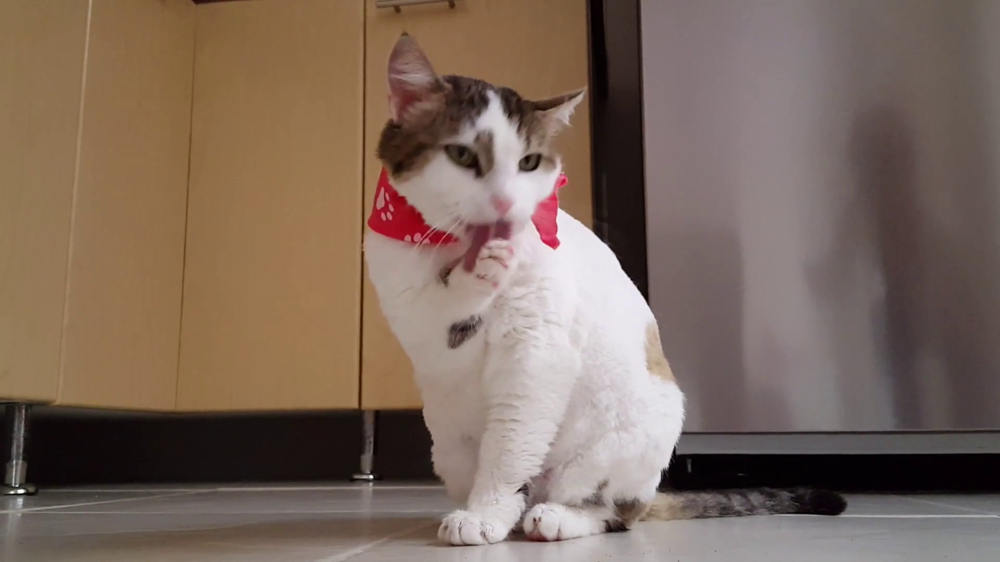

...

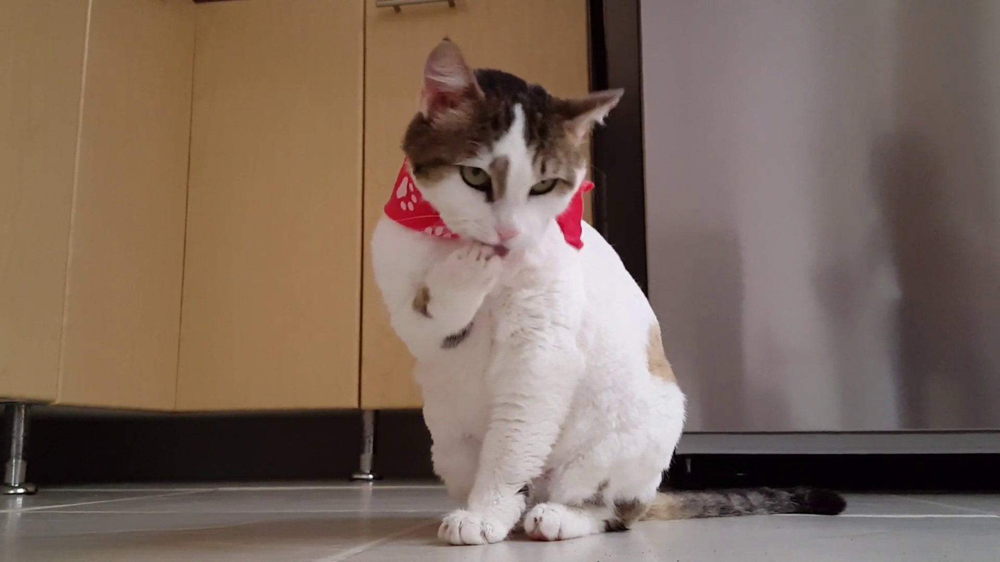

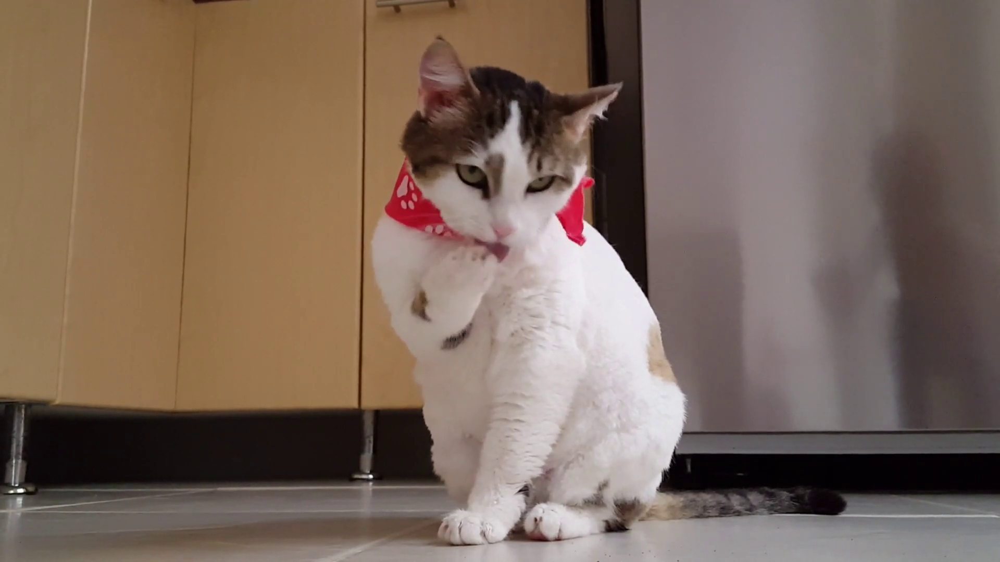

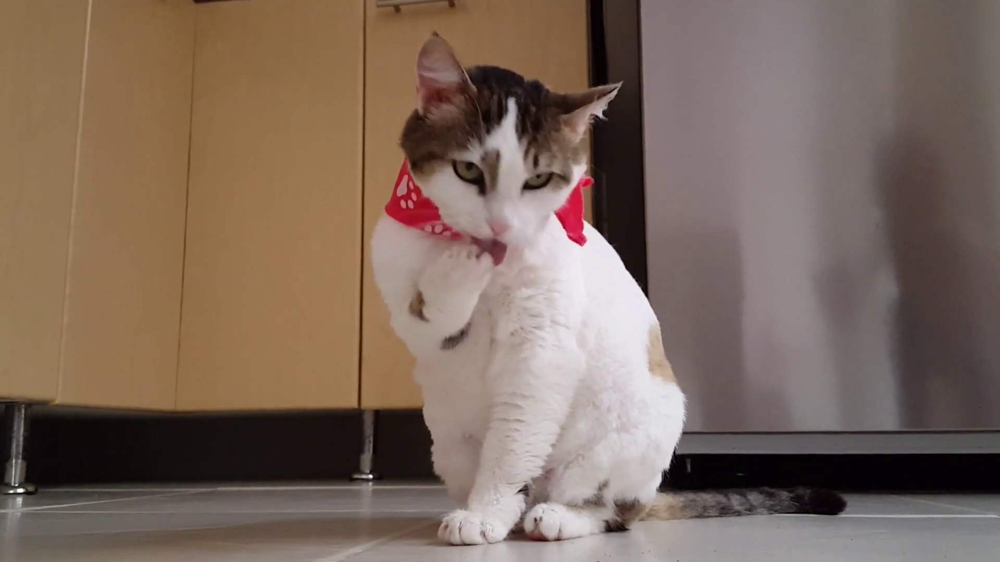

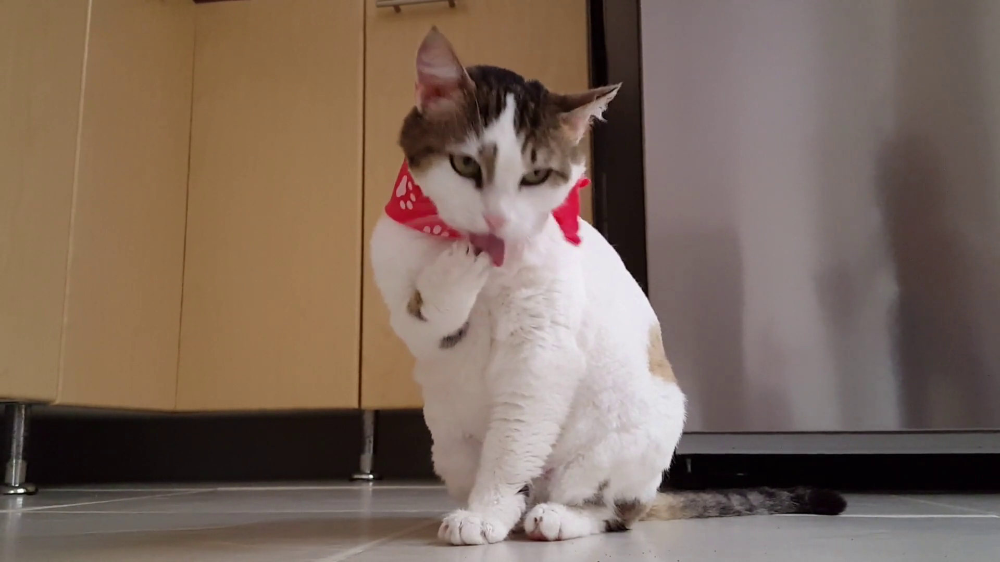

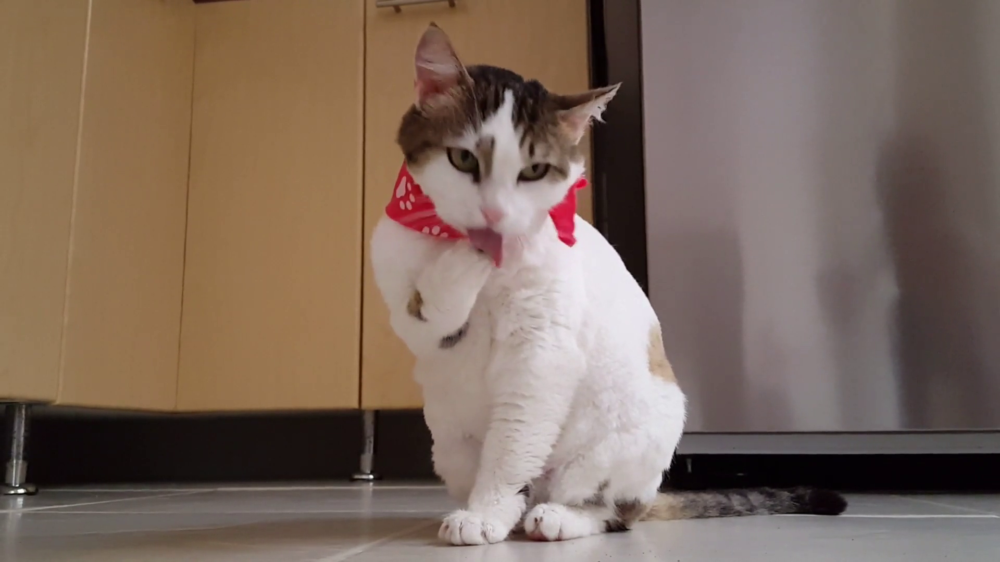

In [4]:
capture=cv.VideoCapture("/content/Cat_Video.mp4")
while(True):
  isTrue,frame=capture.read()
  if not isTrue:
    break
  if cv.waitKey(10)&0xFF==ord('d'):
    break
  cv2_imshow(frame)
capture.release()
cv.destroyAllWindows()

### Resizing and Rescaling the Images and Videos

In [5]:
def rescaleFrame(frame,scale=0.75):
  height=int(frame.shape[0]*scale)
  width=int(frame.shape[1]*scale)
  dim=(width,height)
  return cv.resize(frame,dim,interpolation=cv.INTER_AREA)

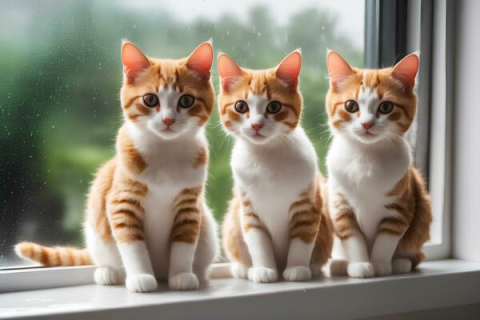

In [6]:
res_img=rescaleFrame(img,scale=0.8)
cv2_imshow(res_img)

In [7]:
def changeRes(width,height):
  capture.set(3,width)
  capture.set(4,height)

### Drawing Shapes and Putting Text on Image
* 1. [] - Filling the Color
* 2. .rectangle() - Drawing a Rectangle
* 3. .circle() - Drawing a Circle
* 4. .line() - Drawing a Line
* 5. .putText() - Inserting a Text

In [8]:
import numpy as np

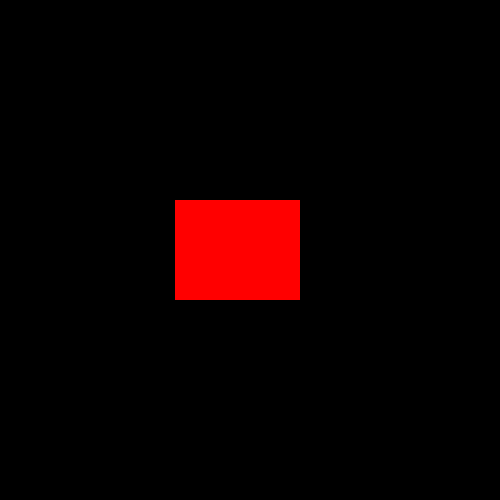

In [9]:
blank=np.zeros((500,500,3),dtype="uint8")
blank[200:300,175:300]=0,0,255
cv2_imshow(blank)

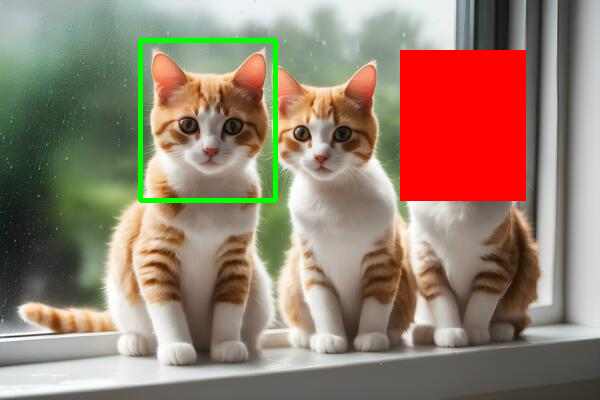

In [10]:
img=cv.imread("/content/Cat.jpg")
cv.rectangle(img,(140,40),(275,200),(0,255,0),thickness=3)
cv.rectangle(img,(400,50),(525,200),(0,0,255),thickness=cv.FILLED)
cv2_imshow(img)

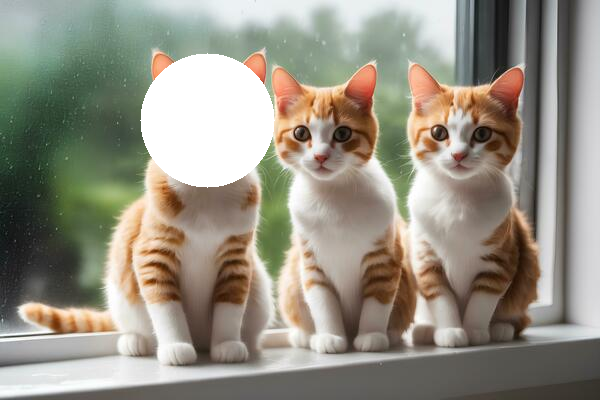

In [11]:
img=cv.imread("/content/Cat.jpg")
cv.circle(img,(207,120),67,(255,255,255),thickness=-1)
cv2_imshow(img)

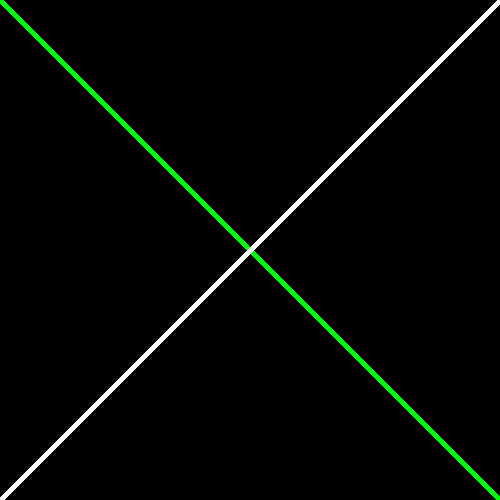

In [12]:
blank=np.zeros((500,500,3),dtype="uint8")
cv.line(blank,(0,0),(500,500),(0,255,0),thickness=3)
cv.line(blank,(0,500),(500,0),(255,255,255),thickness=3)
cv2_imshow(blank)

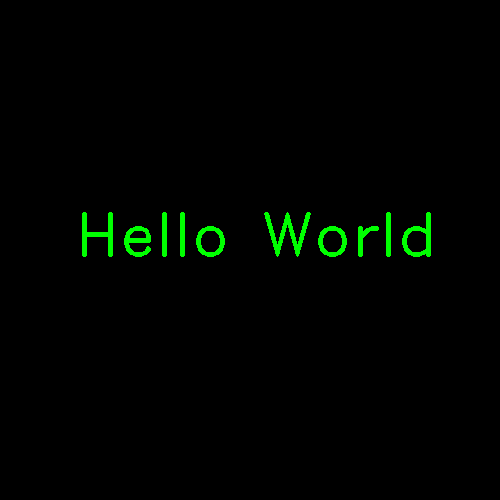

In [13]:
blank=np.zeros((500,500,3),dtype="uint8")
cv.putText(blank,"Hello World",(75,255),cv.FONT_HERSHEY_DUPLEX,2.0,(0,255,0),thickness=2)
cv2_imshow(blank)

### Some Basic Functions in OpenCV
* 1. .cvctColor() - Changing the Color an Image
* 2. .GaussianBlur() - Blurring an Image
* 3. .Canny() - Detecting Edges in Image
* 4. .dilate() - Incresing Edges in Image
* 5. .erode() - Decresing Edges in Image
* 6. .resize() - Resizing an Image
* 7. .[] - Croping an Image

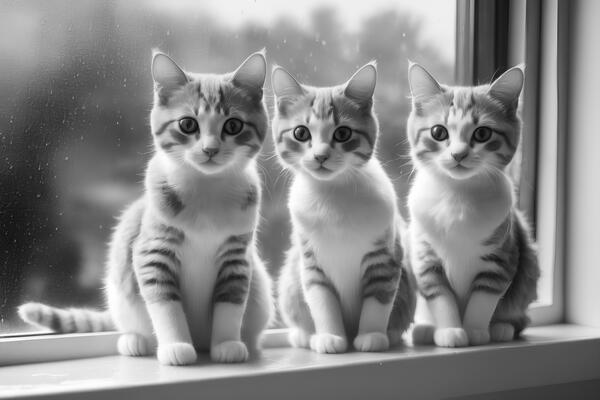

In [14]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
cv2_imshow(gray)

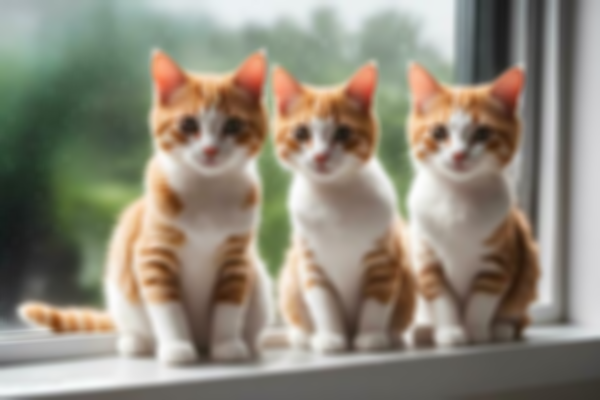

In [15]:
img=cv.imread("/content/Cat.jpg")
blur=cv.GaussianBlur(img,(9,9),cv.BORDER_DEFAULT)
cv2_imshow(blur)

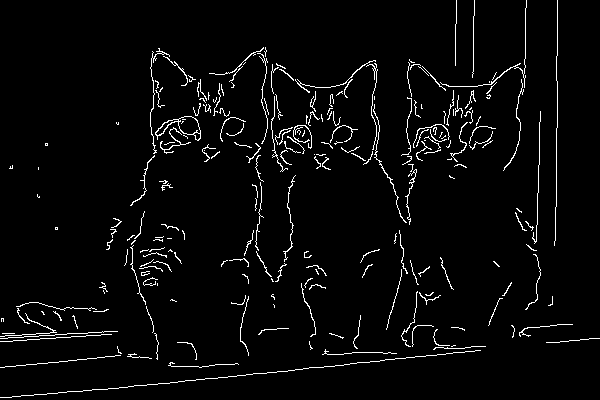

In [16]:
img=cv.imread("/content/Cat.jpg")
can=cv.Canny(img,200,300)
cv2_imshow(can)

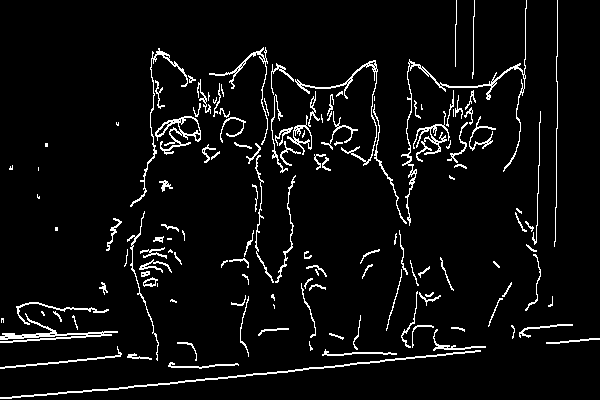

In [17]:
img=cv.imread("/content/Cat.jpg")
dil=cv.dilate(can,(7,7),iterations=1)
cv2_imshow(dil)

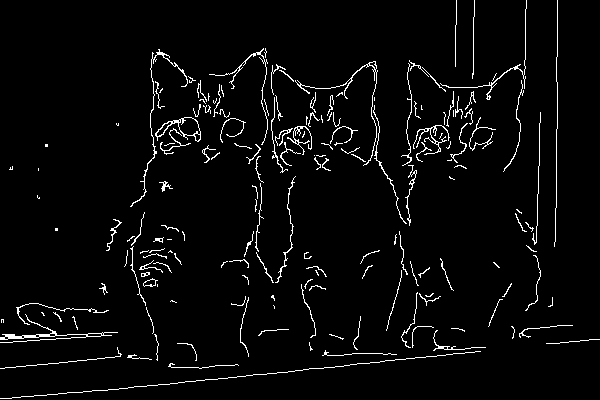

In [18]:
img=cv.imread("/content/Cat.jpg")
ero=cv.erode(dil,(7,7),iterations=1)
cv2_imshow(ero)

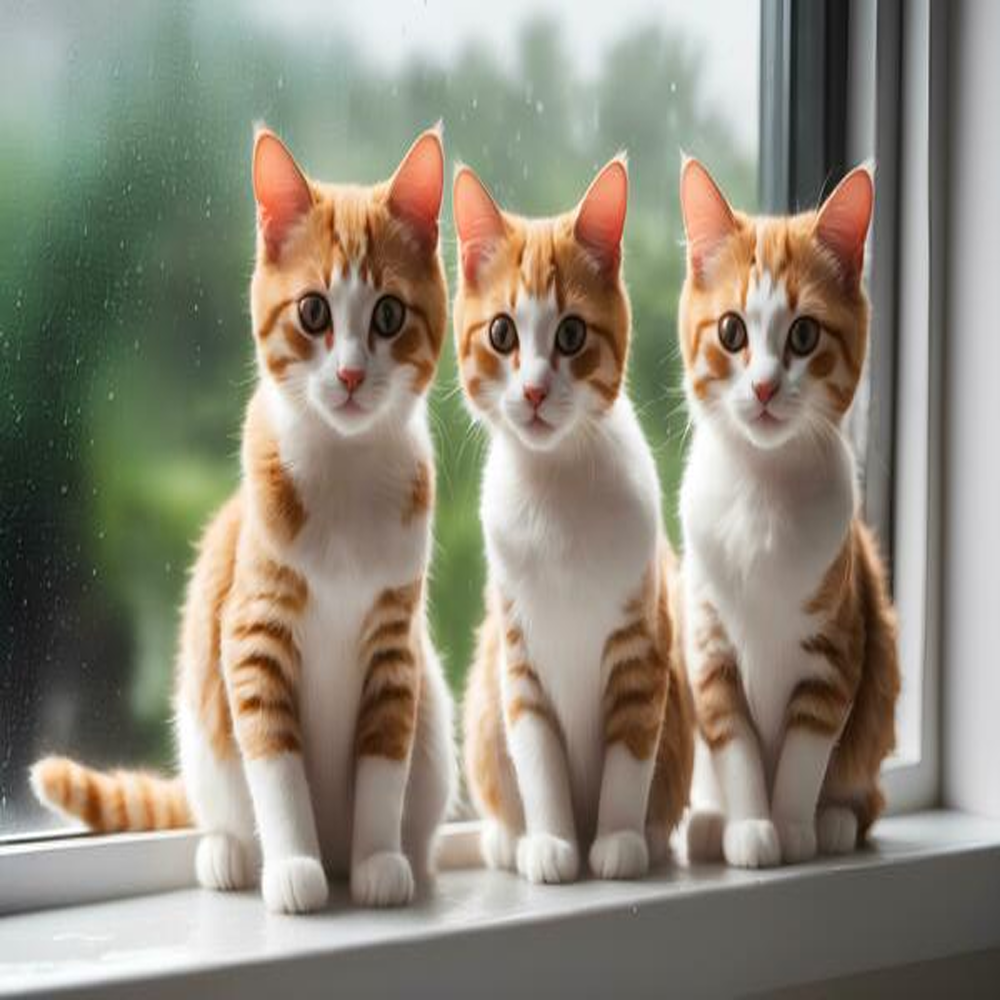

In [19]:
img=cv.imread("/content/Cat.jpg")
res=cv.resize(img,(1000,1000),interpolation=cv.INTER_CUBIC)
cv2_imshow(res)

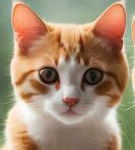

In [20]:
img=cv.imread("/content/Cat.jpg")
crop=img[50:200,140:275]
cv2_imshow(crop)

#### Image Transfomation Functions
* 1. Translation - .float32(),.warpAffine()
* 2. Rotation - .getRotationMatrix2D(),.warpAffine()
* 3. Resize - .resize()
* 4. Flipping - .flip()
* 5. Cropping - []

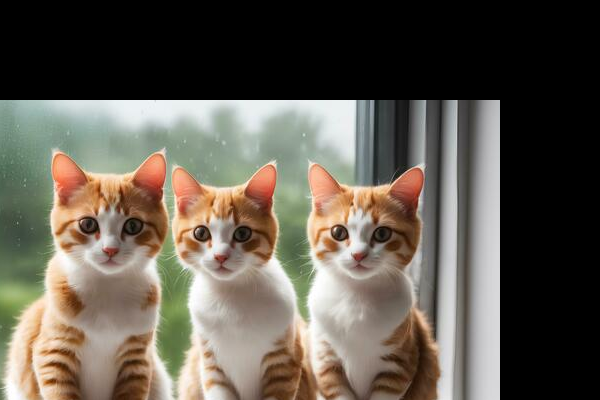

In [21]:
def translation(image,x,y):
  transMat=np.float32([[1,0,x],[0,1,y]])
  dim=(img.shape[1],img.shape[0])
  return cv.warpAffine(img,transMat,dim)
img=cv.imread("/content/Cat.jpg")
tra=translation(img,-100,100)
cv2_imshow(tra)

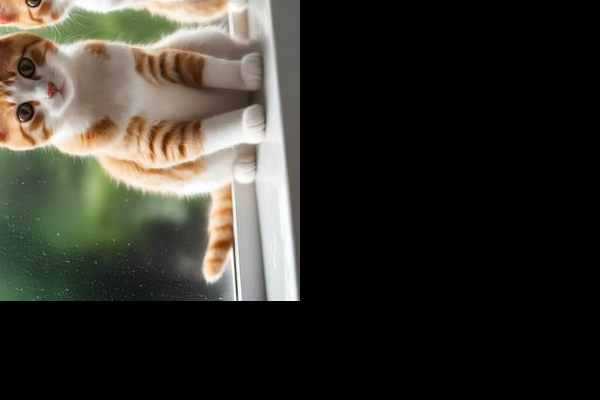

In [22]:
def rotation(image,angle,point=None):
  dim=(img.shape[1],img.shape[0])
  if point is None:
    point=(img.shape[1]//2,img.shape[0]//2)
  rotMat=cv.getRotationMatrix2D(point,angle,1.0)
  return cv.warpAffine(img,rotMat,dim)
img=cv.imread("/content/Cat.jpg")
rot=rotation(img,90,(100,200))
cv2_imshow(rot)

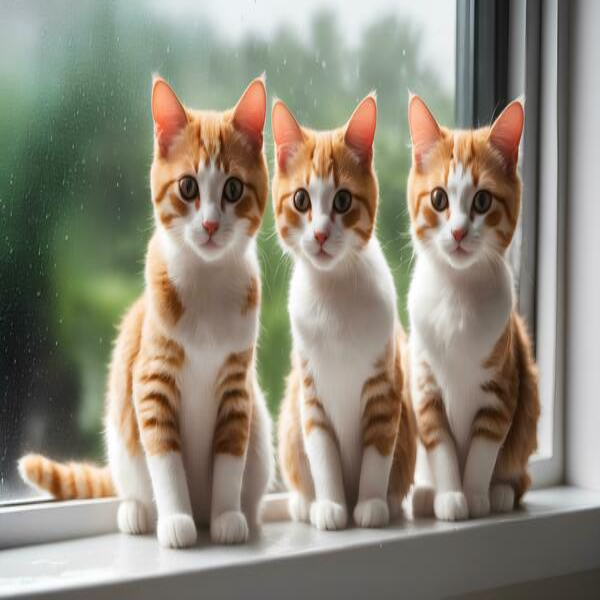

In [23]:
img=cv.imread("/content/Cat.jpg")
res=cv.resize(img,(600,600),interpolation=cv.INTER_LINEAR)
cv2_imshow(res)

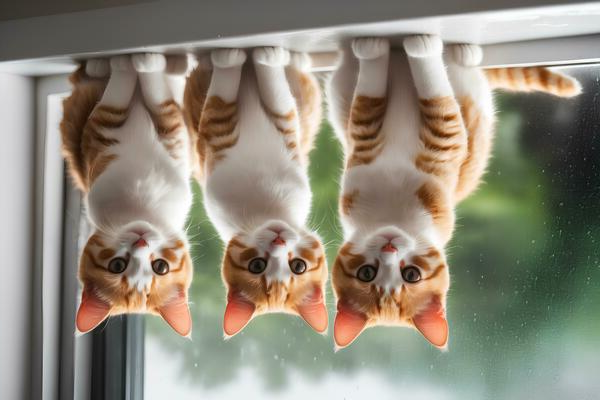

In [24]:
img=cv.imread("/content/Cat.jpg")
fl=cv.flip(img,-1)
cv2_imshow(fl)

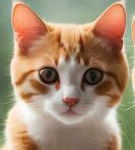

In [25]:
img=cv.imread("/content/Cat.jpg")
crop=img[50:200,140:275]
cv2_imshow(crop)

#### Contour Detection
* 1. Gray->Canny->Contour
* 2. Gray->Blur->Canny->Contour
* 3. Gray->Threshold->Contour

459 contours found in Image


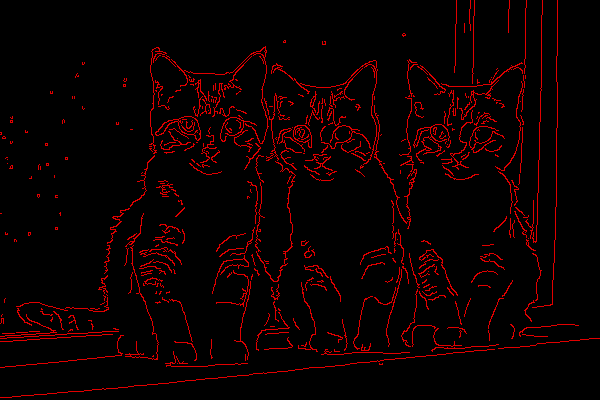

In [26]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
can=cv.Canny(gray,125,175)
contours,hierarchies=cv.findContours(can,cv.RETR_LIST,cv.CHAIN_APPROX_NONE)
print(f'{len(contours)} contours found in Image')
blank=np.zeros(img.shape,dtype="uint8")
draw=cv.drawContours(blank,contours,-1,(0,0,225),1)
cv2_imshow(draw)

246 contours found in Image


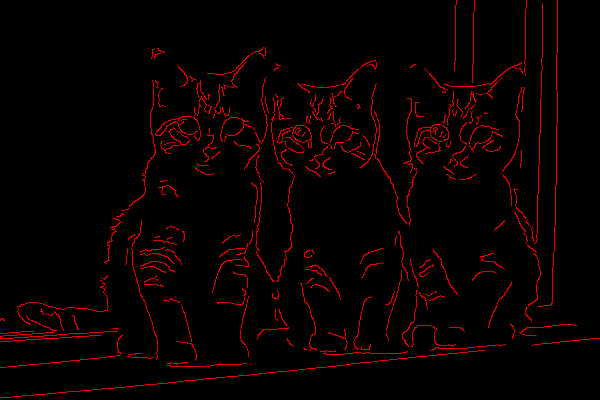

In [27]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
blur=cv.GaussianBlur(gray,(3,3),cv.BORDER_DEFAULT)
can=cv.Canny(blur,125,175)
contours,hierarchies=cv.findContours(can,cv.RETR_LIST,cv.CHAIN_APPROX_NONE)
print(f'{len(contours)} contours found in Image')
blank=np.zeros(img.shape,dtype="uint8")
draw=cv.drawContours(blank,contours,-1,(0,0,225),1)
cv2_imshow(draw)

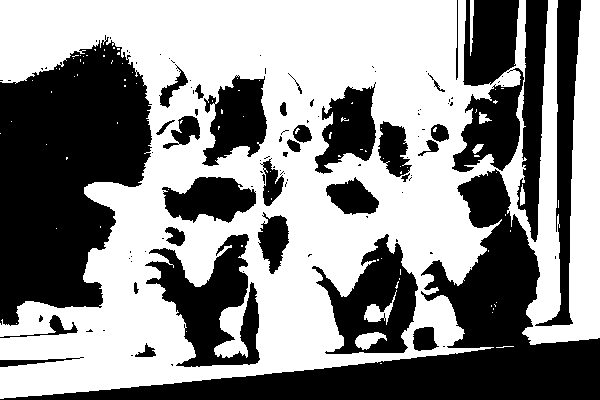

251 contours found in Image


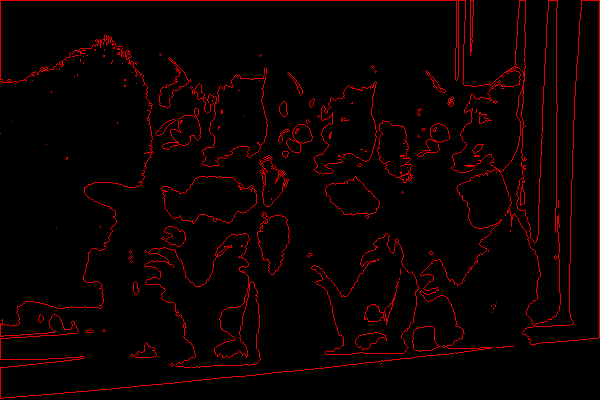

In [28]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
ret,thres=cv.threshold(gray,125,255,cv.THRESH_BINARY)
cv2_imshow(thres)
contours,hierarchies=cv.findContours(thres,cv.RETR_LIST,cv.CHAIN_APPROX_NONE)
print(f'{len(contours)} contours found in Image')
blank=np.zeros(img.shape,dtype="uint8")
draw=cv.drawContours(blank,contours,-1,(0,0,225),1)
cv2_imshow(draw)

#### Color Spaces
* 1. BGR(Blue-Green-Red) - Displaying Image (Default in OpenCV)
* 2. RGB(Red-Green-Blue) - Displaying Image (Default in File Formats)
* 3. Gray Scale - Edge Detection (Retain only Brightness)
* 4. HSV(Hue-Seperation-Value) - Color Segmentation (Hue-Color Type in Angle,Seperation-Intensity,Value-Brightness)
* 5. LAB(Lightness A&B) - Image Enchanement (L-Brightness,A-Green to Red,B-Blue to Yellow)

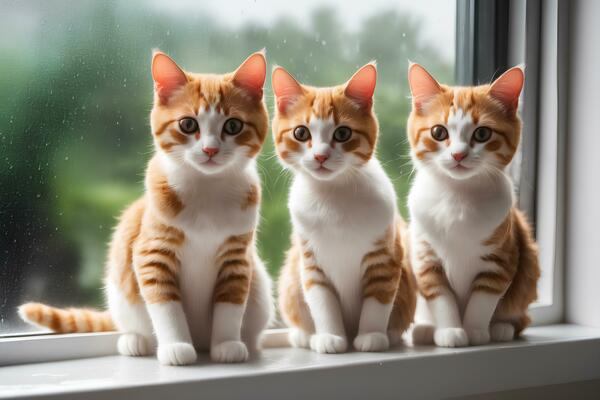

In [29]:
bgr=cv.imread("/content/Cat.jpg")
cv2_imshow(bgr)

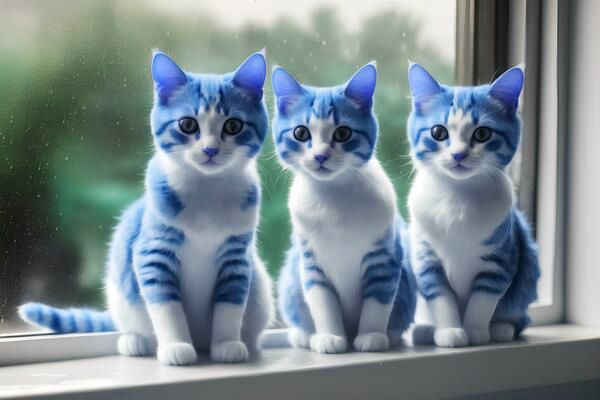

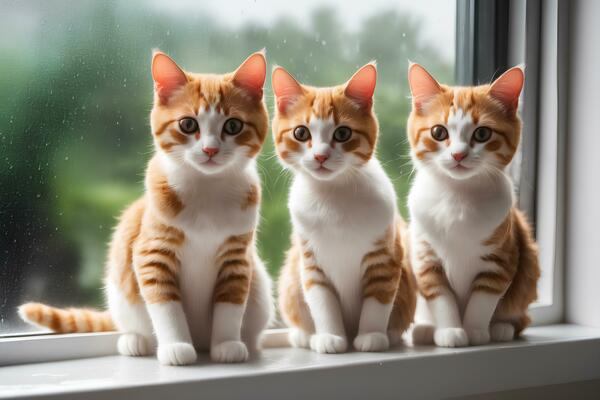

In [30]:
img=cv.imread("/content/Cat.jpg")
rgb=cv.cvtColor(img,cv.COLOR_BGR2RGB)
cv2_imshow(rgb)
bgr=cv.cvtColor(rgb,cv.COLOR_RGB2BGR)
cv2_imshow(bgr)

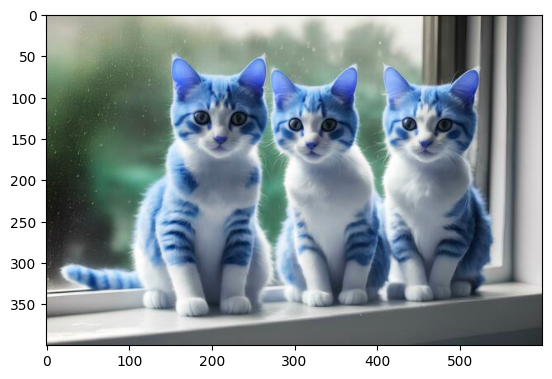

In [31]:
import matplotlib.pyplot as plt
bgr=cv.imread("/content/Cat.jpg")
plt.imshow(bgr)
plt.show()

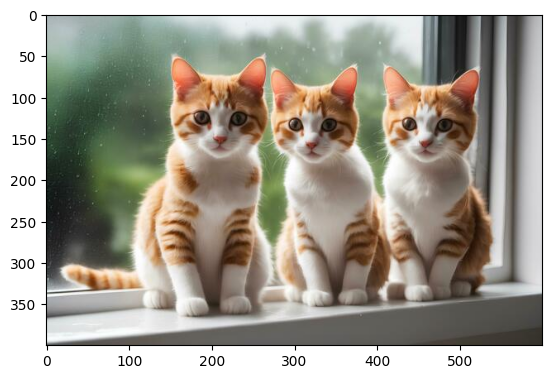

In [32]:
import matplotlib.pyplot as plt
img=cv.imread("/content/Cat.jpg")
rgb=cv.cvtColor(img,cv.COLOR_BGR2RGB)
plt.imshow(rgb)
plt.show()

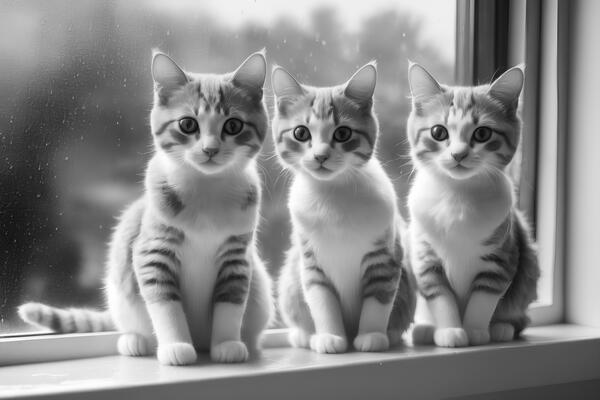

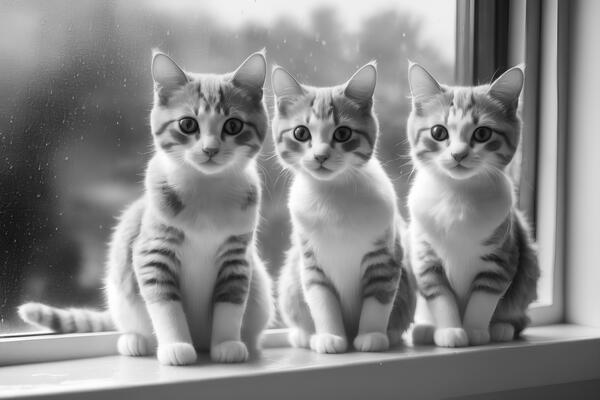

In [33]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
cv2_imshow(gray)
bgr=cv.cvtColor(gray,cv.COLOR_GRAY2BGR)
cv2_imshow(bgr)

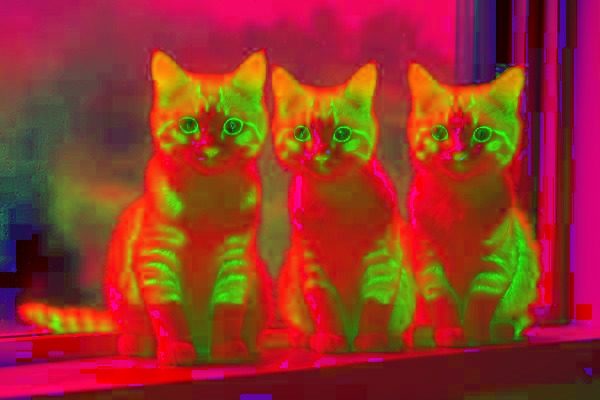

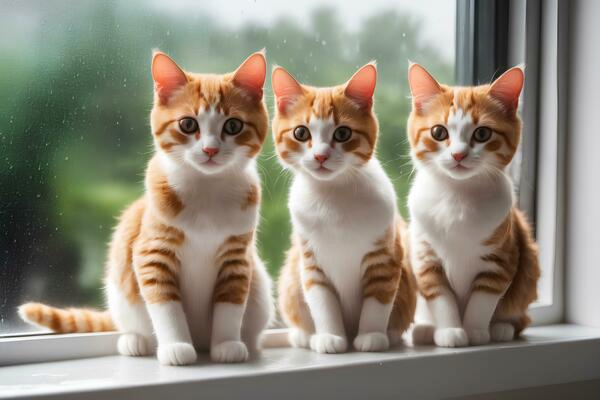

In [34]:
img=cv.imread("/content/Cat.jpg")
hsv=cv.cvtColor(img,cv.COLOR_BGR2HSV)
cv2_imshow(hsv)
bgr=cv.cvtColor(hsv,cv.COLOR_HSV2BGR)
cv2_imshow(bgr)

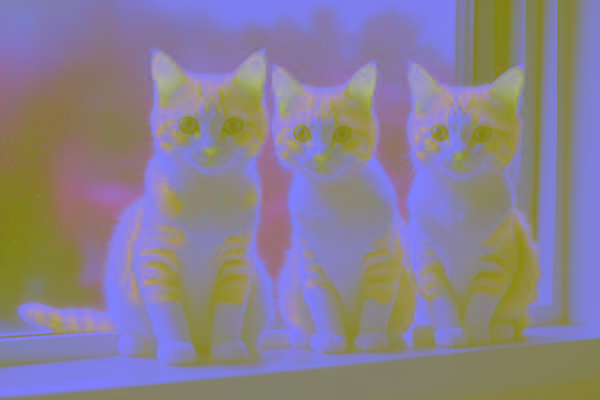

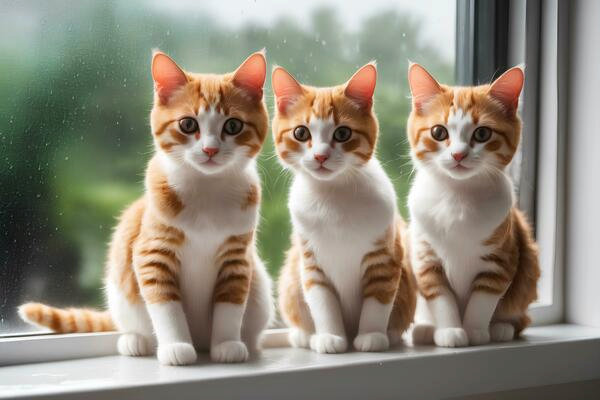

In [35]:
img=cv.imread("/content/Cat.jpg")
lab=cv.cvtColor(img,cv.COLOR_BGR2LAB)
cv2_imshow(lab)
bgr=cv.cvtColor(lab,cv.COLOR_LAB2BGR)
cv2_imshow(bgr)

#### Split and Merge the Image
* 1. .split() - Split the BGR Image into B,G,R Channels and View the B,G,R Channels in BGR Format
* 2. .merge() - Merge the B,G,R Channels into BGR Image
* 3. .merge() - View the B,G,R Channels in BGR Format

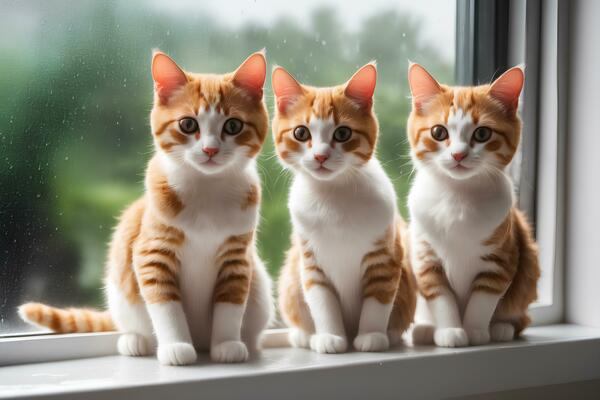

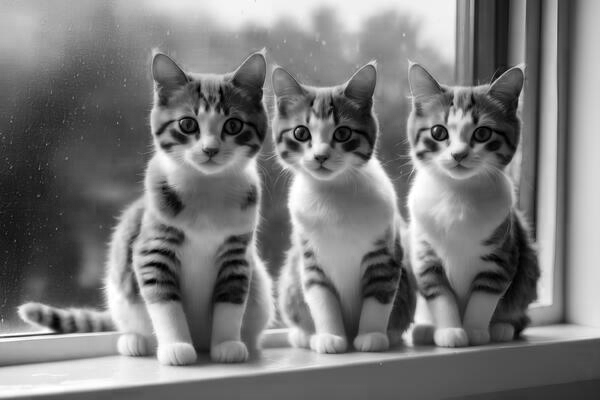

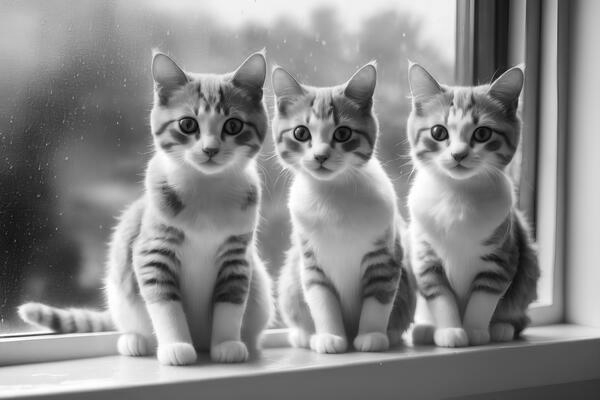

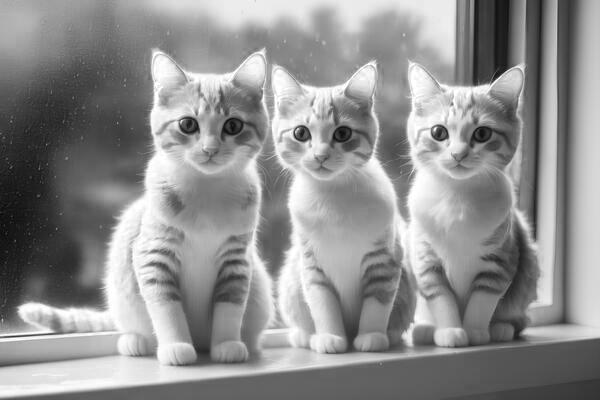

In [36]:
img=cv.imread("/content/Cat.jpg")
cv2_imshow(img)
b,g,r=cv.split(img)
cv2_imshow(b)
cv2_imshow(g)
cv2_imshow(r)

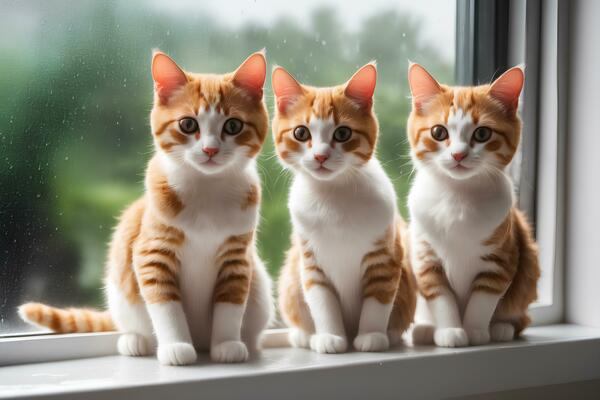

In [37]:
mer=cv.merge([b,g,r])
cv2_imshow(mer)

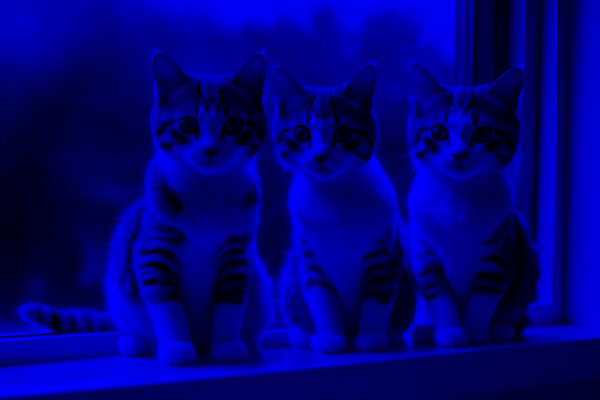

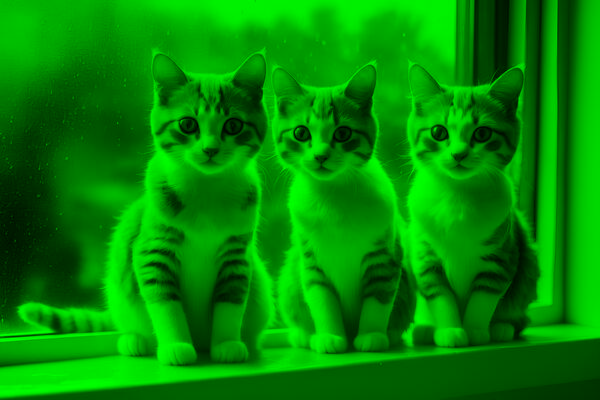

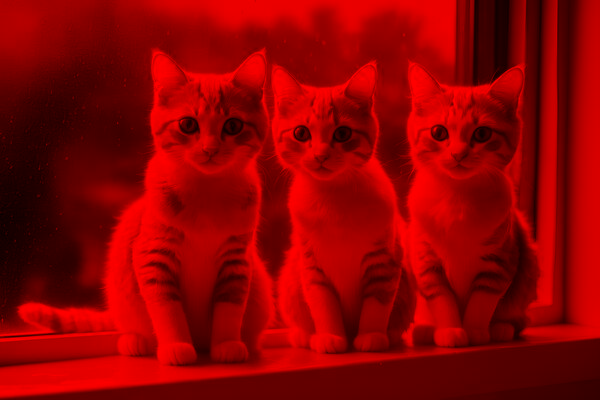

In [38]:
blank=np.zeros(img.shape[:2],dtype="uint8")
blue=cv.merge([b,blank,blank])
green=cv.merge([blank,g,blank])
red=cv.merge([blank,blank,r])
cv2_imshow(blue)
cv2_imshow(green)
cv2_imshow(red)

#### Blurring/Smoothing Images
* 1. .blur() - Average Blur(Smooth the Image Evenly - Average of the Surrounding Pixels in Kernel)
* 2. .GaussianBlur() - Gaussian Blur(Natural Blur - Average of the Product of the Weights of the Sorrounding Pixels)
* 3. .medianBlur() - Median Blur(Remove Salt and Pepper Noise and Retain the Edges - Median of the Surrounding Pixels)
* 4. .bilateralFilter() - Bilateral Filer(Preserve Sharp Edges - Apply Blur in Spatial Domain and Color Domain)

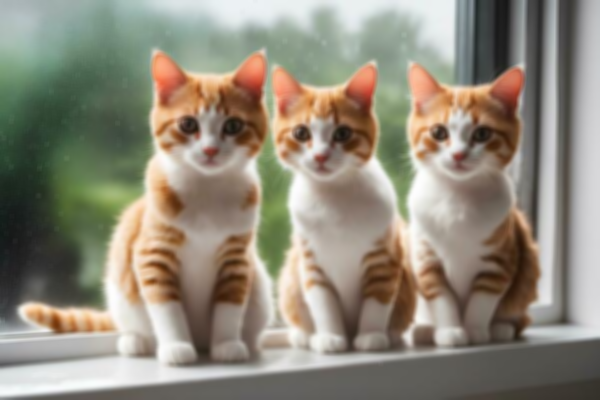

In [39]:
img=cv.imread("/content/Cat.jpg")
blur=cv.blur(img,(5,5))
cv2_imshow(blur)

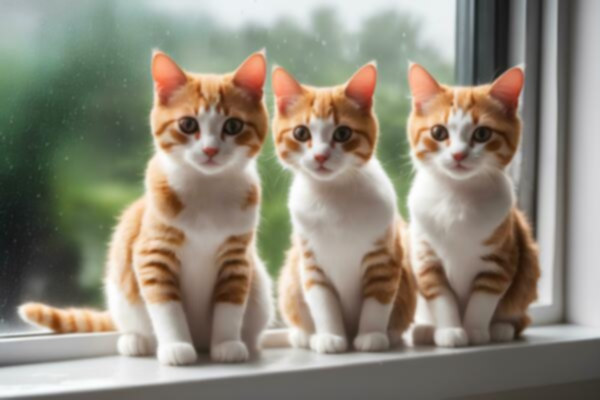

In [40]:
img=cv.imread("/content/Cat.jpg")
gauss=cv.GaussianBlur(img,(5,5),0)
cv2_imshow(gauss)

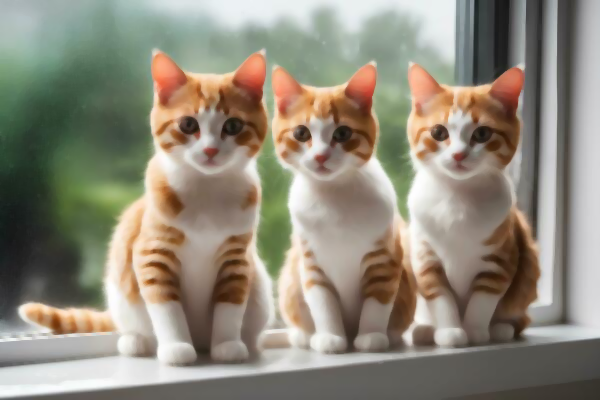

In [41]:
img=cv.imread("/content/Cat.jpg")
med=cv.medianBlur(img,5)
cv2_imshow(med)

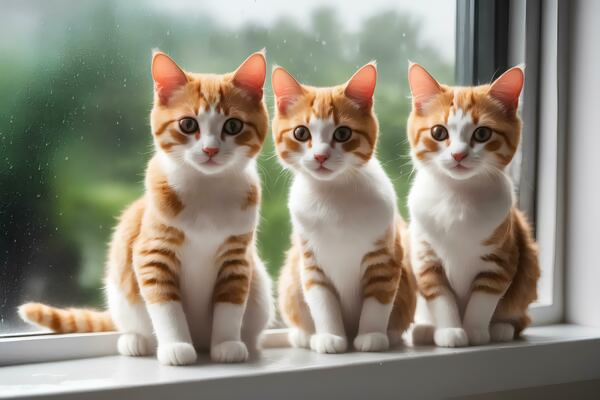

In [42]:
img=cv.imread("/content/Cat.jpg")
bil=cv.bilateralFilter(img,7,15,15)
cv2_imshow(bil)

#### Bitwise Operations
* 1. .bitwise_and() - Intersecting Regions of Two Images
* 2. .bitwise_or() - Intersecting Regions and Non-Intersecting Regions of Two Images
* 3. .bitwise_xor() - Non-Intersecting Regions of Two Images
* 4. .bitwise_not() - Inversion of an Image

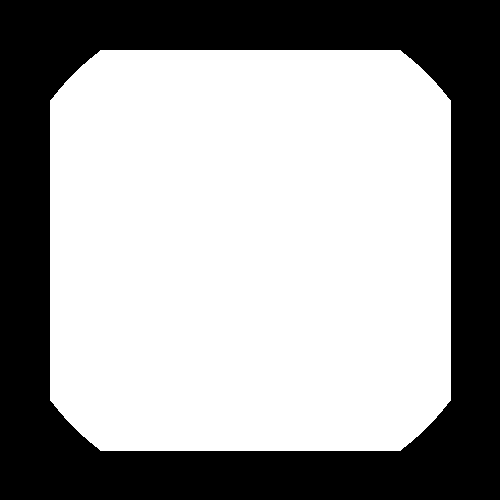

In [43]:
blank=np.zeros((500,500),dtype="uint8")
circle=cv.circle(blank.copy(),(250,250),250,255,-1)
rectangle=cv.rectangle(blank.copy(),(50,50),(450,450),255,-1)
band=cv.bitwise_and(circle,rectangle)
cv2_imshow(band)

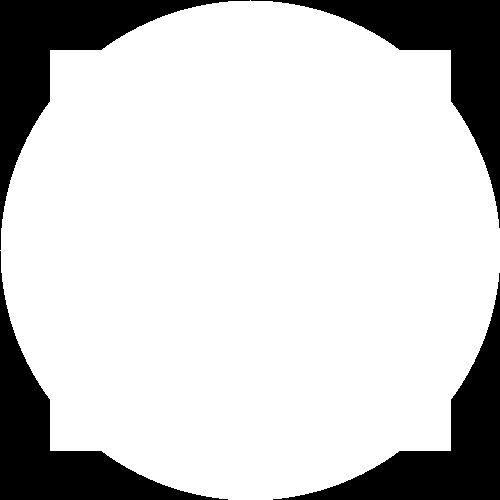

In [44]:
blank=np.zeros((500,500),dtype="uint8")
circle=cv.circle(blank.copy(),(250,250),250,255,-1)
rectangle=cv.rectangle(blank.copy(),(50,50),(450,450),255,-1)
bor=cv.bitwise_or(circle,rectangle)
cv2_imshow(bor)

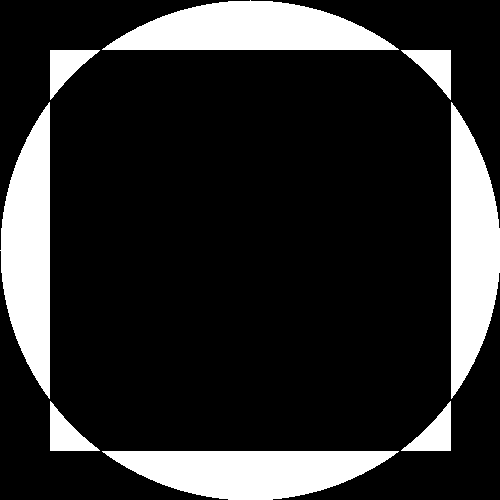

In [45]:
blank=np.zeros((500,500),dtype="uint8")
circle=cv.circle(blank.copy(),(250,250),250,255,-1)
rectangle=cv.rectangle(blank.copy(),(50,50),(450,450),255,-1)
bxor=cv.bitwise_xor(circle,rectangle)
cv2_imshow(bxor)

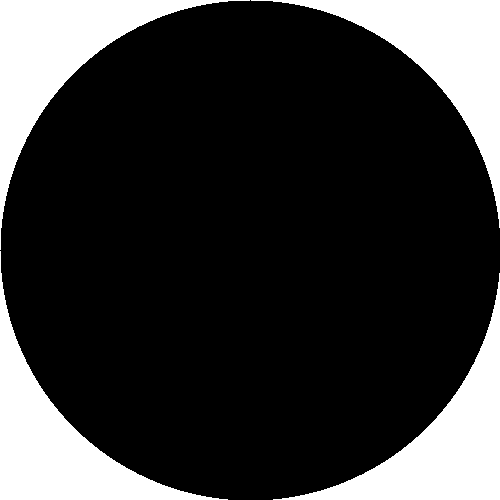

In [46]:
blank=np.zeros((500,500),dtype="uint8")
circle=cv.circle(blank.copy(),(250,250),250,255,-1)
rectangle=cv.rectangle(blank.copy(),(50,50),(450,450),255,-1)
bnot=cv.bitwise_not(circle)
cv2_imshow(bnot)

#### Masking

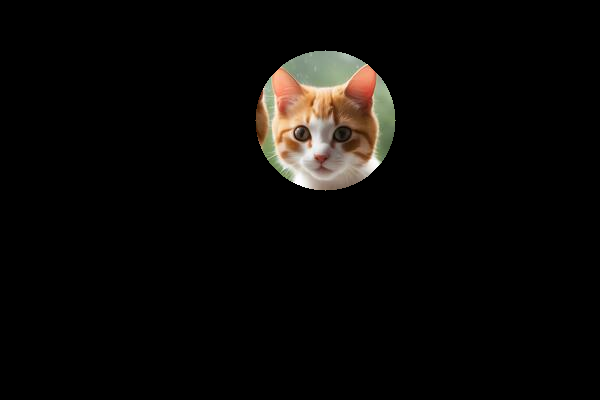

In [47]:
img=cv.imread("/content/Cat.jpg")
blank=np.zeros((img.shape[:2]),dtype="uint8")
mask=cv.circle(blank,(325,120),70,255,-1)
masked_image=cv.bitwise_and(img,img,mask=mask)
cv2_imshow(masked_image)

#### Histogram
* 1. Gray Scale Image
* 2. BGR Image

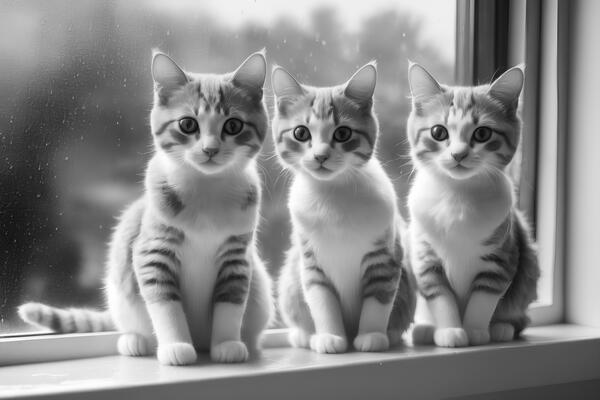

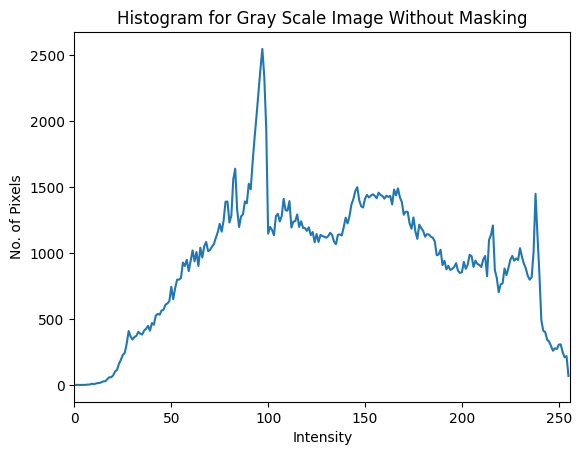

In [48]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
cv2_imshow(gray)
hist=cv.calcHist([gray],[0],None,[256],[0,256])
plt.title("Histogram for Gray Scale Image Without Masking")
plt.xlabel("Intensity")
plt.ylabel("No. of Pixels")
plt.xlim([0,256])
plt.plot(hist)
plt.show()

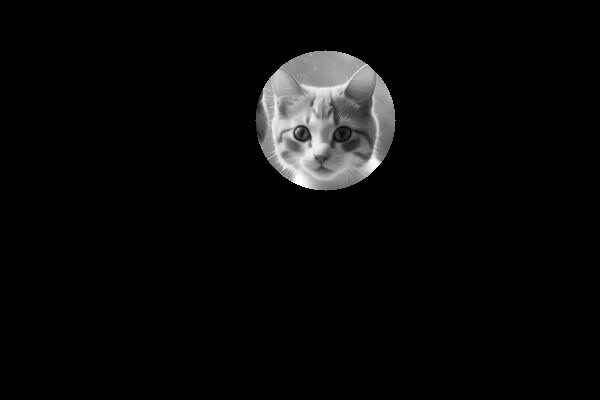

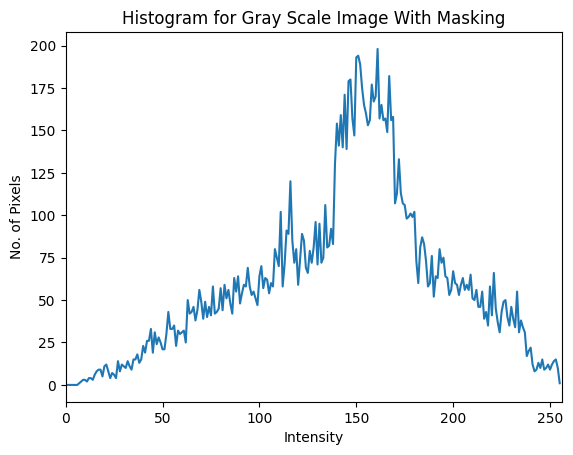

In [49]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
blank=np.zeros((img.shape[:2]),dtype="uint8")
mask=cv.circle(blank,(325,120),70,255,-1)
masked_image=cv.bitwise_and(gray,gray,mask=mask)
cv2_imshow(masked_image)
hist=cv.calcHist([gray],[0],masked_image,[256],[0,256])
plt.title("Histogram for Gray Scale Image With Masking")
plt.xlabel("Intensity")
plt.ylabel("No. of Pixels")
plt.xlim([0,256])
plt.plot(hist)
plt.show()

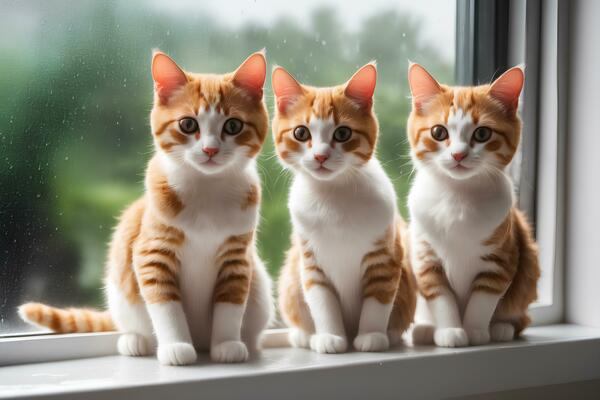

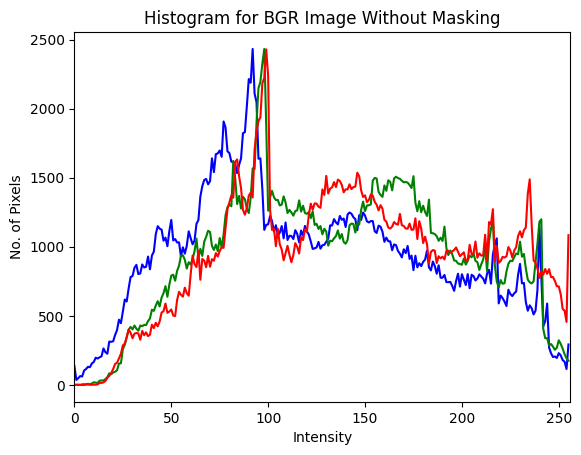

In [50]:
img=cv.imread("/content/Cat.jpg")
cv2_imshow(img)
colors=('b','g','r')
for i,color in enumerate(colors):
  hist=cv.calcHist([img],[i],None,[256],[0,256])
  plt.plot(hist,color=color)
  plt.xlim([0,256])
plt.title("Histogram for BGR Image Without Masking")
plt.xlabel("Intensity")
plt.ylabel("No. of Pixels")
plt.show()

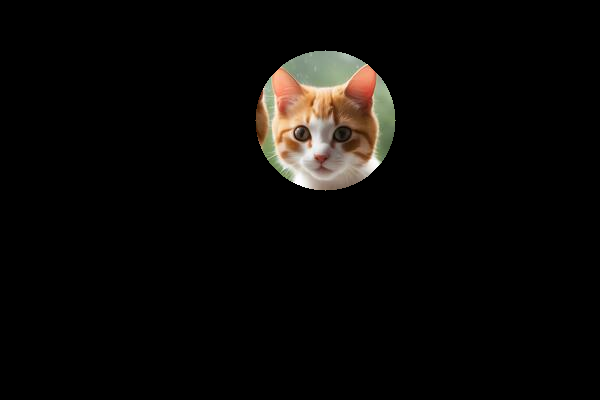

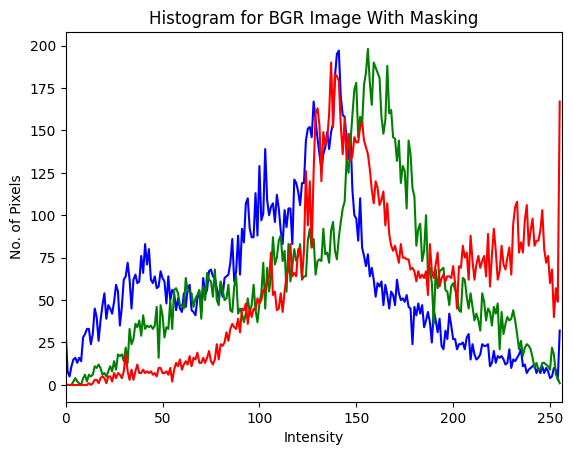

In [51]:
img=cv.imread("/content/Cat.jpg")
blank=np.zeros((img.shape[:2]),dtype="uint8")
mask=cv.circle(blank,(325,120),70,255,-1)
masked_image=cv.bitwise_and(img,img,mask=mask)
cv2_imshow(masked_image)
colors=('b','g','r')
for i,color in enumerate(colors):
  hist=cv.calcHist([img],[i],mask,[256],[0,256])
  plt.plot(hist,color=color)
  plt.xlim([0,256])
plt.title("Histogram for BGR Image With Masking")
plt.xlabel("Intensity")
plt.ylabel("No. of Pixels")
plt.show()

#### Thresholding/Binarizing
* 1. Simple Thresholding
* 2. Adaptative Threshold

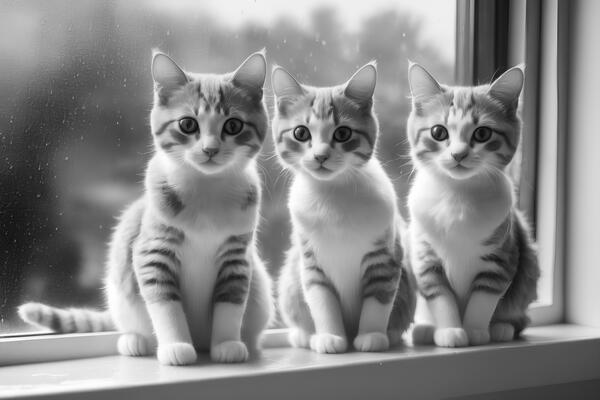

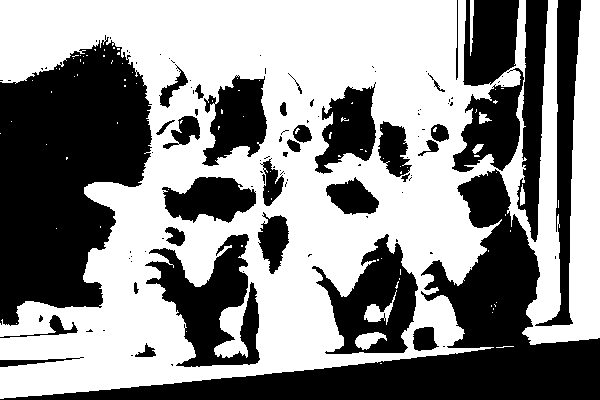

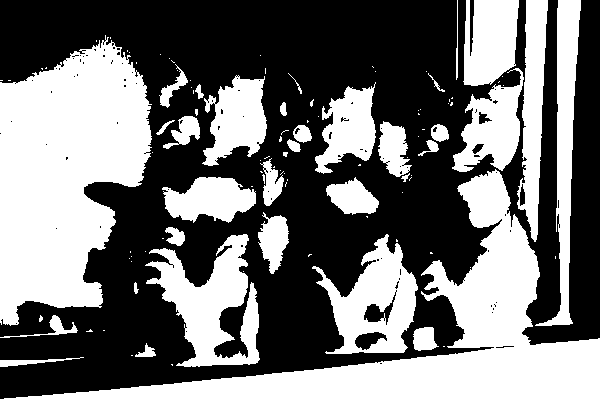

In [52]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
cv2_imshow(gray)
threshold,thres=cv.threshold(gray,125,255,cv.THRESH_BINARY)
cv2_imshow(thres)
threshold,thres_inv=cv.threshold(gray,125,255,cv.THRESH_BINARY_INV)
cv2_imshow(thres_inv)

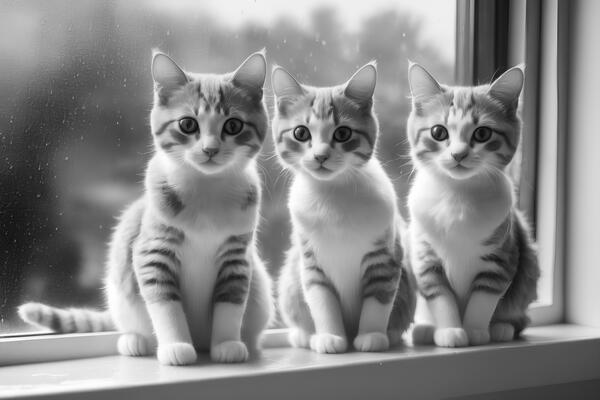

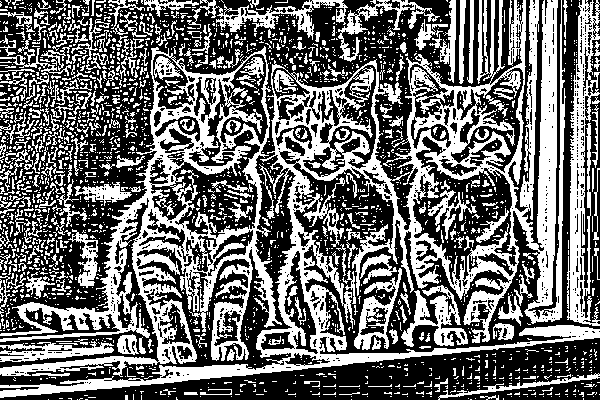

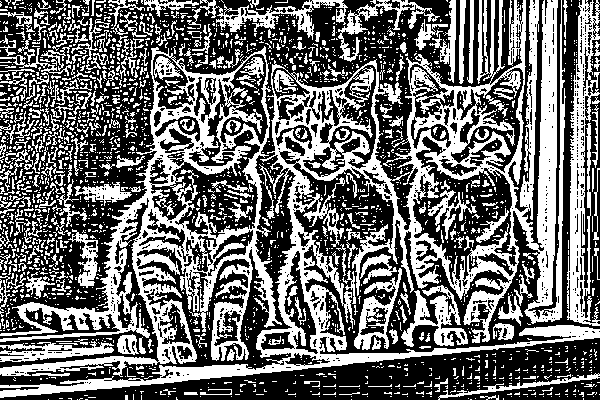

In [53]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
cv2_imshow(gray)
thres=cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_MEAN_C,cv.THRESH_BINARY,7,0)
cv2_imshow(thres)
thres_inv=cv.adaptiveThreshold(gray,255,cv.ADAPTIVE_THRESH_MEAN_C,cv.THRESH_BINARY,7,0)
cv2_imshow(thres_inv)

#### Edge Detection Using Gradients
* 1. .Laplacian() - Second Order Derivative and Detect Edges in all Directions
* 2. .Sobel() - First Order Derivative and Detect Edges in only x and y Directions

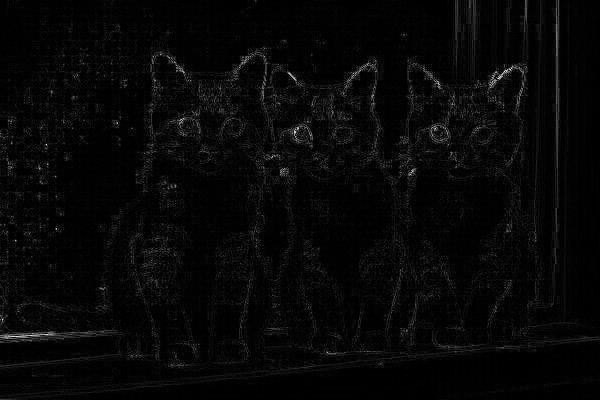

In [54]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
lap=cv.Laplacian(gray,cv.CV_64F)
lap=np.uint8(np.absolute(lap))
cv2_imshow(lap)

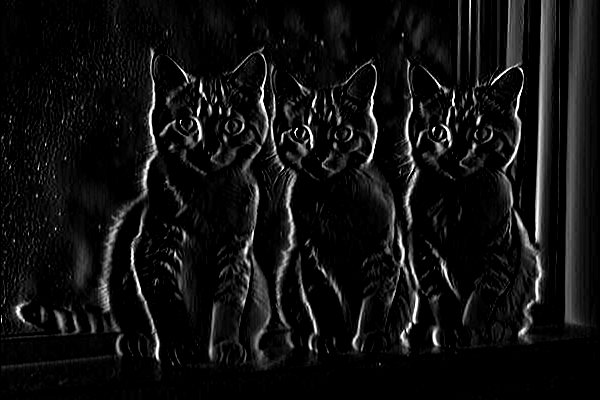

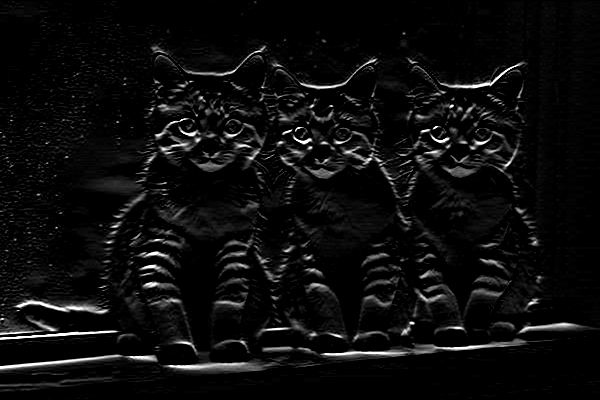

/usr/local/lib/python3.10/dist-packages/google/colab/patches/__init__.py:18: RuntimeWarning: invalid value encountered in cast
  a = a.clip(0, 255).astype('uint8')


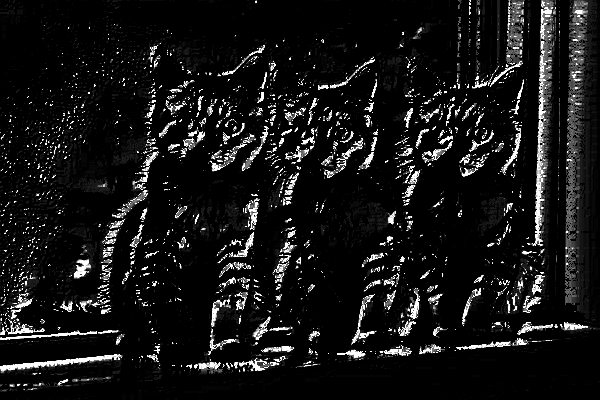

In [55]:
img=cv.imread("/content/Cat.jpg")
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
sobelx=cv.Sobel(gray,cv.CV_64F,1,0)
sobely=cv.Sobel(gray,cv.CV_64F,0,1)
sobel=cv.bitwise_or(sobelx,sobely)
cv2_imshow(sobelx)
cv2_imshow(sobely)
cv2_imshow(sobel)